# Tien leerbare schaalfactoren per MX-groep / A32
## SVHN · CNN-8 · vijf volledige epochs

Iedere groep van **32 gewichten** kiest één factor uit **×1, ×2, ×4, ×8, ×16, ×32, ×64, ×128, ×256 en ×512**. De E4M3-bron wordt uit de FP32-master bepaald met dezelfde preprocessing en encoder als eerder. E2M3 behoudt de hoogste twee exponentbits; E2M1 ontstaat door twee mantissabits van E2M3 te verwijderen. Beide lagere modi delen **E8M0-broncode + gekozen offset 0..9**. De E4M3-bronschaal zelf wordt niet geleerd.

De **4.080 FP32-hulpwaarden** $\theta_b$ beginnen exact op **6**, dus aanvankelijk ×64, zonder extra willekeurige initialisatie. Hun bereik is nu $[0,9]$. De forward rondt af naar het dichtstbijzijnde gehele getal; halve waarden gaan naar de hogere offset. De benaderde schaalgradient is $\ln(2)\sum_{i\in b}g_iq_i$ per lagere modus. De twee bijdragen worden opgeteld. Na één gezamenlijke Adam-update worden de hulpwaarden teruggebracht binnen $[0,9]$. Activaties zijn **A32**, masters en optimizerstaat **FP32**.

Dit notebook leest alleen JSON/CSV. Het start geen training, opent geen dataset en laadt geen modelcheckpoint. Het vergelijkt met de echte eerdere **binaire pilot** en dezelfde vroege epochs van de **vaste ×32/×64-trainingen**. De template wordt zonder uitgevoerde cellen geleverd. Voer zelf **Run All** uit.


In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_learned_scale10_pilot5\\20261104_185824_003629_joint_run')
SAVE_FIGURES = False  # Zet op True om figuren in een nieuwe analysemap te bewaren.


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass
    def display(value):
        print(value)

# De helper werkt vanuit de pakketmap, projectroot, resultaatmap of uitgepakte feedbackmap.
roots = []
if RUN_DIR is not None and Path(RUN_DIR).expanduser().is_dir():
    roots.append(Path(RUN_DIR).expanduser().resolve())
roots += [Path.cwd(), *Path.cwd().parents]
candidates = []
for root in dict.fromkeys(roots):
    candidates += [root / 'notebook_support.py',
                   root / 'software_checks' / 'mx_triple_learned_scale10_pilot5_v1' / 'notebook_support.py',
                   root / 'runner_source' / 'notebook_support.py']
helper_path = next((p for p in candidates if p.is_file()), None)
if helper_path is None:
    raise FileNotFoundError('Houd notebook_support.py bij de notebook of open vanuit de projectmap.')
helper_name = '_mx_triple_learned_scale10_pilot5_analysis_helper'
spec = importlib.util.spec_from_file_location(helper_name, helper_path)
if spec is None or spec.loader is None:
    raise FileNotFoundError(f'Analysehelper ontbreekt: {helper_path}')
ns = importlib.util.module_from_spec(spec)
sys.modules[helper_name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
print('Ingelezen resultaatmap:', run.path)
display(Markdown(ns.status_markdown(run)))
display(ns.protocol_table(run))
display(Markdown('### Meldingen en ontbrekende gegevens'))
display(ns.diagnostics_table(run))


Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_learned_scale10_pilot5\20261104_185824_003629_joint_run


### Opgeslagen SVHN-run — herkomst volgens het runrapport

Runstatus: **PASS** · Analysefouten: **0**. Laatste ingelezen testepoch: **5**.

**Epoch100 niet gemeten als bevestigd eindresultaat.** De laatste beschikbare epoch en het door E4M3 gekozen beste checkpoint blijven zichtbaar. Er wordt geen ontbrekende accuracy voorspeld. De vijf-epochpilot is volgens het runrapport voltooid.

Deze analyse leest uitsluitend opgeslagen JSON/CSV. Zij start geen training en laadt geen model of checkpoint.

,Onderdeel,Opgeslagen configuratie
0,Gewichtsmodi,"MXFP8_E4M3, MXFP6_E2M3, MXFP4_E2M1"
1,Gewichtsroute,Actuele E4M3-bron → exponent-MSB-truncatie naa...
2,Geleerde correctie,"Eén FP32 θ per B32-groep; θ∈[0,9], begin6; afr..."
3,Gedeelde lagere schaal,E2M3 en E2M1 delen dezelfde blokkeuze. De E4M3...
4,Mastergradient,"Identity-STE naar G(W), zonder extra schaalfac..."
5,Schaalgradient,ln(2) × som(gradient_q × werkelijk gebruikt q)...
6,Gradientnormalisatie,Geen extra LSQ-normalisatie; geen gemiddelde i...
7,Schaalgrenzen,"θ na Adam projecteren op [0,9]; E8M0-code in b..."
8,Trainbare parameters,132954 basis + 4080 schaalproxies = 137034
9,Activaties / masters / proxies,A32 / FP32 / FP32


### Meldingen en ontbrekende gegevens

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


## Epoch 5 en beste checkpoint gekozen door E4M3

Het beste checkpoint is het **eerste strikte maximum van de E4M3-testaccuracy binnen de pilot**. Een gelijke score vervangt het eerdere checkpoint niet. E2M3 en E2M1 worden op precies dezelfde epoch gerapporteerd; hun eigen hoogste scores worden niet samengevoegd met een andere E4M3-epoch.

De officiële testset wordt volgens het bestaande protocol voor checkpointselectie gebruikt. De beste score is daardoor geen onafhankelijke testschatting na selectie. Het vaste eindpunt epoch 5 staat er apart naast. Dit is een vroege trainingsproef, geen bewijs welke schaalfactor na honderd epochs het beste is.


,Rol,Controlepunt,Epoch,Gewichtsformaat,Testaccuracy [%],Correct / n,Harde test-CE,Selectiebron,Checkpoint
0,last_epoch,Epoch 5,5,MXFP8_E4M3,92.655194,24.120 / 26.032,0.251728,checkpoint_selection.json,last_checkpoint.pt
1,last_epoch,Epoch 5,5,MXFP6_E2M3,91.425937,23.800 / 26.032,0.288205,checkpoint_selection.json,last_checkpoint.pt
2,last_epoch,Epoch 5,5,MXFP4_E2M1,91.602643,23.846 / 26.032,0.285720,checkpoint_selection.json,last_checkpoint.pt
3,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP8_E4M3,92.655194,24.120 / 26.032,0.251728,checkpoint_selection.json,best_checkpoint.pt
4,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP6_E2M3,91.425937,23.800 / 26.032,0.288205,checkpoint_selection.json,best_checkpoint.pt
5,best_E4M3_test,Beste checkpoint gekozen door E4M3 binnen de p...,5,MXFP4_E2M1,91.602643,23.846 / 26.032,0.285720,checkpoint_selection.json,best_checkpoint.pt


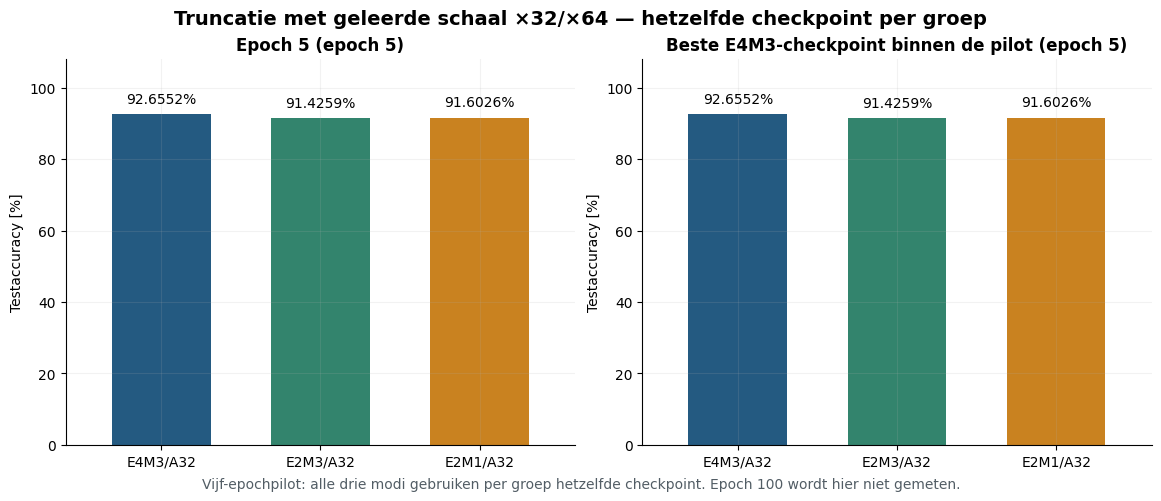

In [3]:
display(ns.checkpoint_table(run).round({'Testaccuracy [%]': 6, 'Harde test-CE': 8}))
figures['checkpoint_accuracy'] = ns.plot_checkpoint_accuracy(run)
display(figures['checkpoint_accuracy'])
plt.close(figures['checkpoint_accuracy'])


## Vergelijking met twee leerbare keuzes en vaste ×32/×64

De binaire referentie is de werkelijk uitgevoerde vijf-epochpilot. De twee vaste referenties komen uit eerdere volledige trainingen. Voor alle vergelijkingen gebruiken we **alleen epochs 1–5**, en bij een onvoltooide run alleen de gezamenlijk bereikte vroege epochs. De meegeleverde bestanden en hun herkomst worden met hashes gecontroleerd.

De grafieken tonen het volledige vroege accuracyverloop en de drie accuracies op **epoch 5** én op **het checkpoint gekozen door E4M3 binnen datzelfde interval**. De drie precisies van iedere training gebruiken één gezamenlijk checkpoint. De beste checkpoints uit de latere volledige referenties en hun epoch100-scores worden hier niet gebruikt.

De leerbare varianten beginnen op dezelfde factor ×64. De tienkeuzevariant verruimt de toegestane beweging; we voegen geen exploratieruis, extra trainingspasses of extra FP32-schaalparameters toe.


### Tien leerbare keuzes tegenover twee keuzes en vaste factoren

De vaste ×32/×64-referenties zijn volledige trainingen; de binaire referentie is de echte vijf-epochpilot. Hier gebruiken we uitsluitend dezelfde eerste epochs, maximaal vijf. Iedere training kiest één gezamenlijk checkpoint op E4M3 binnen dat vroege interval. 

**Vast ×32: vergelijking bevestigd voor epochs 1–5.**

**Vast ×64: vergelijking bevestigd voor epochs 1–5.**

**Geleerd: 2 keuzes: vergelijking bevestigd voor epochs 1–5.**

De binaire en tienkeuzevariant hebben evenveel FP32-schaalparameters en dezelfde initialisatie θ=6. De tienkeuzevariant kan ook boven6 en onder5 bewegen. Afzonderlijke CUDA-runs zijn niet bitexact gegarandeerd; vijf epochs geven geen definitieve rangschikking.

,Controlepunt,Referentie,Gewichtsformaat,Epoch geleerd,Epoch referentie,Geleerd accuracy [%],Referentie accuracy [%],Verschil tienkeuze − referentie [pp],Geleerd harde CE,Referentie harde CE
0,Epoch 5,Vast ×32,MXFP8_E4M3,5,5,92.655194,92.466964,0.188230,0.251728,0.260174
1,Epoch 5,Vast ×32,MXFP6_E2M3,5,5,91.425937,91.064843,0.361094,0.288205,0.300404
2,Epoch 5,Vast ×32,MXFP4_E2M1,5,5,91.602643,90.719115,0.883528,0.285720,0.316703
3,Beste E4M3 binnen epochs 1–5,Vast ×32,MXFP8_E4M3,5,5,92.655194,92.466964,0.188230,0.251728,0.260174
4,Beste E4M3 binnen epochs 1–5,Vast ×32,MXFP6_E2M3,5,5,91.425937,91.064843,0.361094,0.288205,0.300404
5,Beste E4M3 binnen epochs 1–5,Vast ×32,MXFP4_E2M1,5,5,91.602643,90.719115,0.883528,0.285720,0.316703
6,Epoch 5,Vast ×64,MXFP8_E4M3,5,5,92.655194,93.008605,-0.353411,0.251728,0.243082
7,Epoch 5,Vast ×64,MXFP6_E2M3,5,5,91.425937,91.299170,0.126767,0.288205,0.298985
8,Epoch 5,Vast ×64,MXFP4_E2M1,5,5,91.602643,90.891979,0.710664,0.285720,0.310513
9,Beste E4M3 binnen epochs 1–5,Vast ×64,MXFP8_E4M3,5,5,92.655194,93.008605,-0.353411,0.251728,0.243082


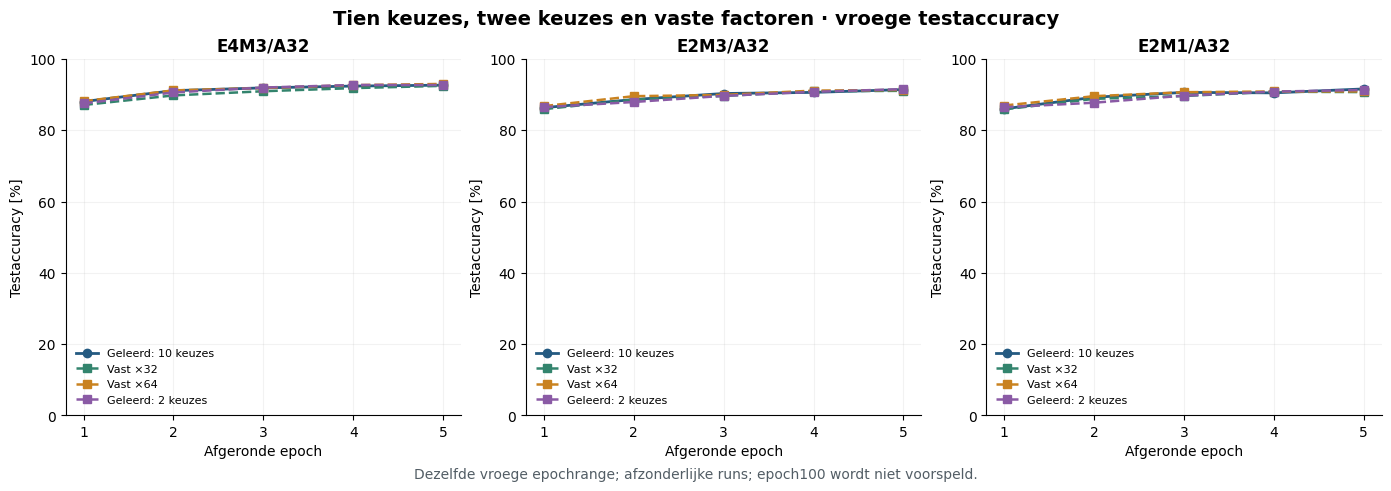

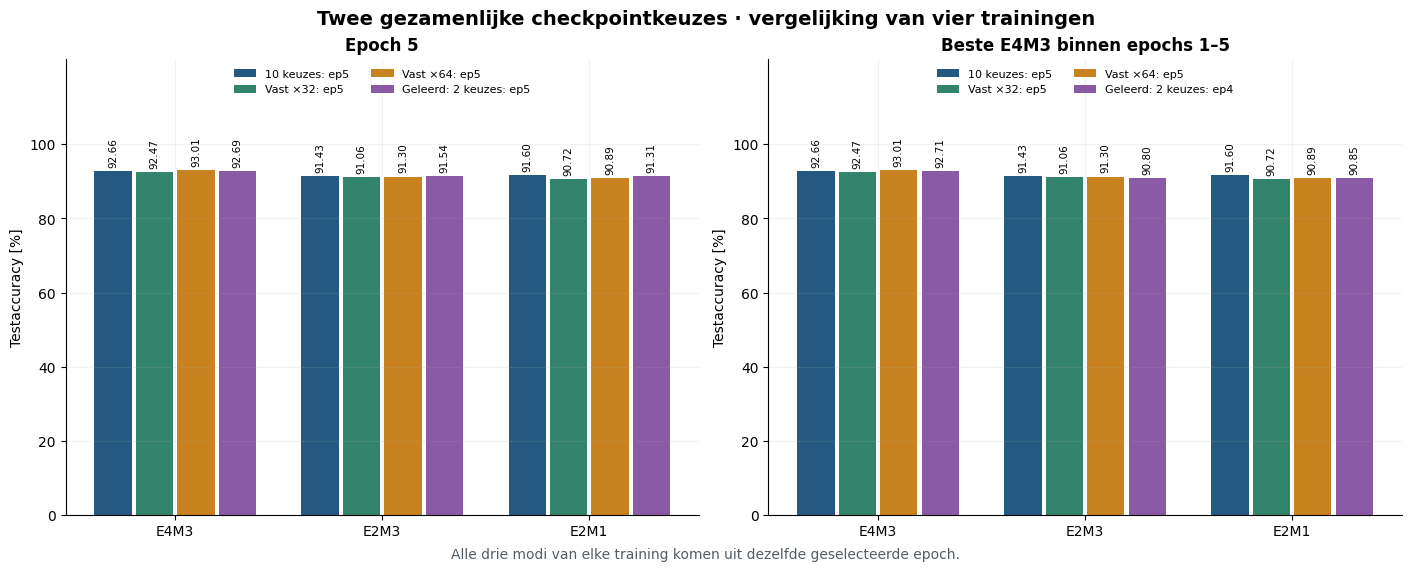

In [4]:
references = ns.load_fixed_references(run)
display(Markdown(ns.comparison_markdown(run, references)))
display(ns.comparison_table(run, references).round(6))
figures['scale_comparison_curves'] = ns.plot_scale_comparison_curves(run, references)
display(figures['scale_comparison_curves'])
plt.close(figures['scale_comparison_curves'])
figures['scale_comparison_checkpoints'] = ns.plot_scale_comparison_checkpoints(run, references)
display(figures['scale_comparison_checkpoints'])
plt.close(figures['scale_comparison_checkpoints'])


## Train- en testaccuracy per modus

De drie modi worden gezamenlijk vanaf een nieuwe initialisatie getraind. Trainaccuracy wordt tijdens de updates verzameld. Testaccuracy wordt na iedere epoch gemeten met de opgeslagen harde blokkeuzes, bevroren evaluatiestaat en volledige testset. De drie modusgebonden BatchNorm-banken leren tijdens de training normaal mee. De E4M3-route blijft direct uit de actuele bron bepaald; E2M3 en E2M1 volgen dezelfde geleerde blokkeuze.


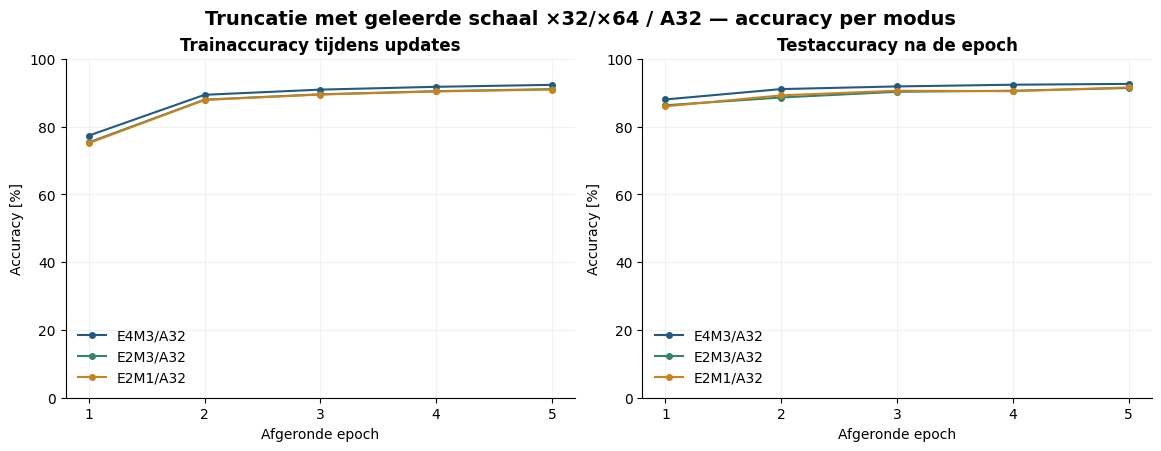

In [5]:
figures['accuracy_curves'] = ns.plot_learning(run)
display(figures['accuracy_curves'])
plt.close(figures['accuracy_curves'])


## Losses: trainingsdoelen onderscheiden van harde test-CE

De trainpass van E4M3 gebruikt harde CE van labels. Daarna leert E2M3 met soft-target CE van de **detached E4M3-softmax**; E2M1 leert met soft-target CE van de **detached E2M3-softmax**. Dit is recursieve distillatie met T=1. De drie gradients worden gesommeerd zonder deling door drie, waarna één Adam-update volgt; er is geen extra FP32-teacherforward.

De drie trainobjectieven staan in afzonderlijke panelen omdat hun targets verschillen. Soft CE is geen harde label-CE en wordt hier ook niet als KL-divergentie aangeduid. **Testloss is voor alle drie modi harde CE van dezelfde labels** en staat daarom samen in één vergelijkbaar paneel.


,epoch,phase,weight_format,objective_type,objective_loss
0,1,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.935609
1,1,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.904042
2,1,train,MXFP8_E4M3,hard_cross_entropy,0.706113
3,1,test,MXFP4_E2M1,hard_cross_entropy,0.457688
4,1,test,MXFP6_E2M3,hard_cross_entropy,0.443862
5,1,test,MXFP8_E4M3,hard_cross_entropy,0.386165
6,2,train,MXFP4_E2M1,recursive_soft_cross_entropy,0.510238
7,2,train,MXFP6_E2M3,recursive_soft_cross_entropy,0.457261
8,2,train,MXFP8_E4M3,hard_cross_entropy,0.348120
9,2,test,MXFP4_E2M1,hard_cross_entropy,0.376875


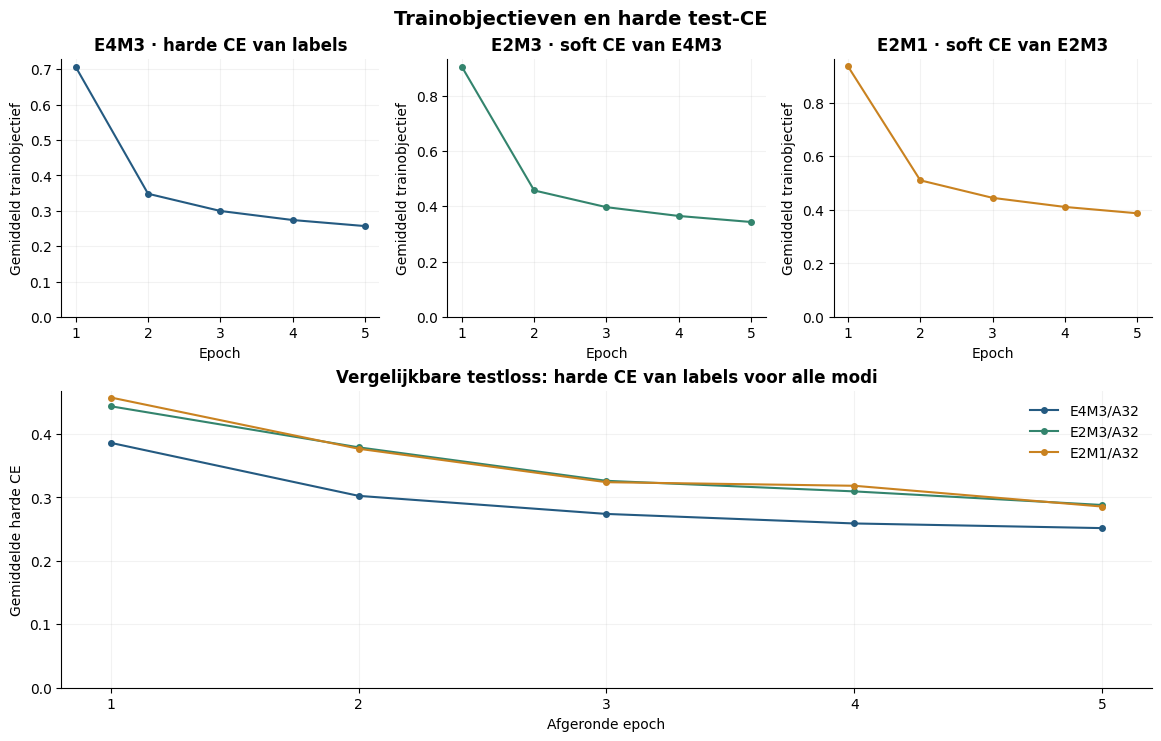

In [6]:
if not run.metrics.empty:
    objective_columns = [key for key in ('epoch', 'phase', 'weight_format', 'objective_type', 'objective_loss') if key in run.metrics]
    display(run.metrics[objective_columns].round({'objective_loss': 8}))
figures['objective_losses'] = ns.plot_objectives(run)
display(figures['objective_losses'])
plt.close(figures['objective_losses'])


## Blijft het netwerk verschillende cijfers voorspellen?

De eerdere post-hocproeven lieten bij sommige routes sterk vertekende of constante voorspellingen zien. Daarom wordt hier per testepoch en per modus bijgehouden hoe de voorspellingen over de tien cijfers verdeeld zijn. Een constante voorspelling is direct zichtbaar als **één gebruikte klasse en 100% concentratie**. De tabel toont ook hoe vaak het dominante cijfer werkelijk in de testset voorkomt.

Dit zijn geaggregeerde tellingen; deze notebook doet geen nieuwe inferentie en leidt er geen per-beeldvergelijking uit af.


,Rol,Epoch,Gewichtsformaat,Voorspelde klassen,Meest voorspelde cijfer,Aandeel dominant cijfer [%],Aandeel dat cijfer in labels [%],Testaccuracy [%],Constante voorspelling,Testbeelden,Tellingen voorspeld cijfer 0..9,Tellingen echt cijfer 0..9
0,last_epoch,5,MXFP8_E4M3,10,1,20.063768,19.587431,92.655194,False,26032,"[1825, 5223, 4120, 2898, 2444, 2319, 2015, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
1,last_epoch,5,MXFP6_E2M3,10,1,20.532422,19.587431,91.425937,False,26032,"[1809, 5345, 4115, 3136, 2358, 2187, 2011, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
2,last_epoch,5,MXFP4_E2M1,10,1,20.217425,19.587431,91.602643,False,26032,"[1780, 5263, 4171, 3036, 2408, 2221, 2060, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
3,best_E4M3_test,5,MXFP8_E4M3,10,1,20.063768,19.587431,92.655194,False,26032,"[1825, 5223, 4120, 2898, 2444, 2319, 2015, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
4,best_E4M3_test,5,MXFP6_E2M3,10,1,20.532422,19.587431,91.425937,False,26032,"[1809, 5345, 4115, 3136, 2358, 2187, 2011, 201...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."
5,best_E4M3_test,5,MXFP4_E2M1,10,1,20.217425,19.587431,91.602643,False,26032,"[1780, 5263, 4171, 3036, 2408, 2221, 2060, 200...","[1744, 5099, 4149, 2882, 2523, 2384, 1977, 201..."


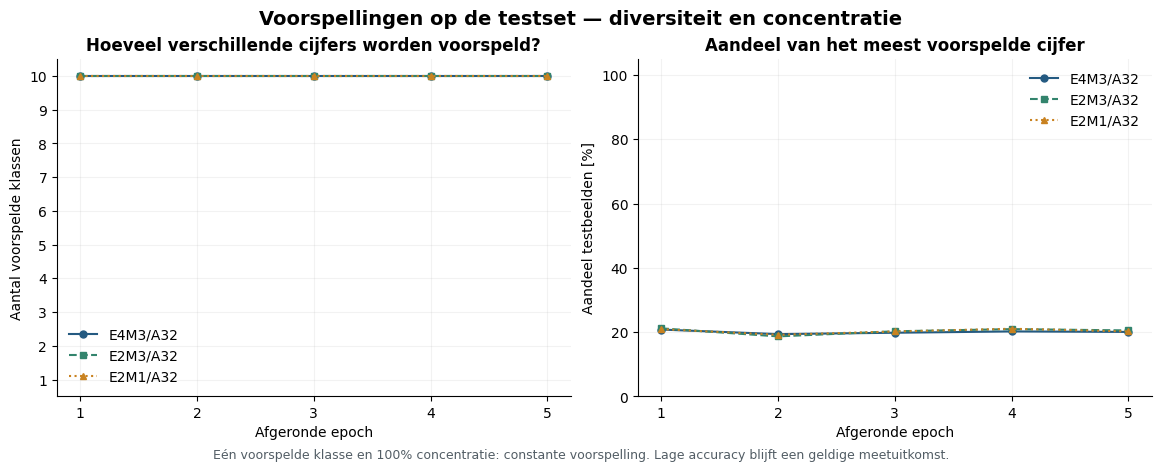

In [7]:
display(ns.prediction_table(run, selected_only=True))
figures['prediction_diversity'] = ns.plot_prediction_diversity(run)
display(figures['prediction_diversity'])
plt.close(figures['prediction_diversity'])


## Welke factoren worden gekozen, en bewegen de hulpwaarden?

De diagnostiek onderscheidt het leersignaal, de continue beweging van θ en de harde keuze. De negen drempels liggen op **0,5; 1,5; …; 8,5**. Een parameter kan bewegen zonder een drempel te passeren. Geen harde omschakeling is daarom geen technische FAIL.

De gestapelde grafieken tonen **alle tien factoren per laag en per epoch**, inclusief epoch0. De histogrammen tonen de volledige θ-verdeling bij initialisatie, bij het E4M3-bestcheckpoint en bij de laatste afgeronde epoch. We onderscheiden groepen die een uiterste factor kiezen van hulpwaarden die exact op de projectiegrens 0 of 9 liggen.

De helper berekent keuzes en samenvattingen opnieuw uit de opgeslagen blokstaat en vergelijkt ze met CSV en history. De pilot hoeft niet alle toegestane factoren daadwerkelijk te bezoeken; de afzonderlijke codeccontroles toetsen hun bereikbaarheid.


**Laatste afgeronde epoch 5 — aantallen per factor:** ×1: **0**, ×2: **0**, ×4: **0**, ×8: **0**, ×16: **0**, ×32: **24**, ×64: **4,051**, ×128: **5**, ×256: **0**, ×512: **0**. Totaal: 4,080 groepen. In de laatste epoch veranderden 4,080 FP32-hulpwaarden. Over de opgeslagen training werden 319 harde keuzewisselingen geteld.

**Uiterste keuzes:** 0 groepen kiezen ×1 en 0 kiezen ×512. **Exact op de projectiegrens:** 0 θ-waarden zijn 0 en 0 zijn 9. Een uiterste keuze betekent dus niet automatisch dat de continue parameter op de grens vastzit.

Een groep kan binnen een epoch meerdere keren wisselen. Het aantal wissels, het aantal unieke wisselende groepen en het verschil tussen de twee epochgrenzen zijn afzonderlijke metingen. Een sprong van offset5 naar7 telt als één wissel met sprongafstand2. Geen harde wissel sluit een continue θ-verplaatsing niet uit; geen van deze diagnostieken bewijst accuracywinst.

,epoch,layer,blocks,theta_min,theta_max,theta_mean,theta_std,theta_changed_blocks,theta_update_l2,count_x1,...,net_choice_changes,choice_flips_during_epoch,choice_jump_distance_during_epoch,max_choice_jump,unique_blocks_switched_during_epoch,projected_values_during_epoch,scale_grad_l2_min,scale_grad_l2_max,scale_grad_nonzero_blocks_max,scale_lr
0,1,layers.3,64,5.804925,6.132620,6.000456,0.074868,64,0.598952,0,...,0,0,0,0,0,0,0.001367,0.045660,64,0.001
1,1,layers.6,80,5.732961,6.254140,5.995086,0.103172,80,0.923846,0,...,0,0,0,0,0,0,0.001257,0.035379,80,0.001
2,1,layers.10,160,5.808043,6.196605,6.003044,0.087851,160,1.111904,0,...,0,0,0,0,0,0,0.001051,0.032405,160,0.001
3,1,layers.13,288,5.789283,6.201264,6.000201,0.070598,288,1.198097,0,...,0,0,0,0,0,0,0.000964,0.029367,288,0.001
4,1,layers.16,288,5.790607,6.224548,6.002642,0.070949,288,1.204882,0,...,0,0,0,0,0,0,0.000811,0.020751,288,0.001
5,1,layers.20,3200,5.738734,6.156298,5.937685,0.071525,3200,5.366260,0,...,0,0,0,0,0,0,0.001066,0.015179,3200,0.001
6,2,layers.3,64,5.737979,6.233635,6.001119,0.111167,64,0.576458,0,...,0,0,0,0,0,0,0.006121,0.034053,64,0.001
7,2,layers.6,80,5.604126,6.394607,5.993080,0.161194,80,0.764213,0,...,0,0,0,0,0,0,0.007852,0.029473,80,0.001
8,2,layers.10,160,5.722795,6.290697,6.004219,0.129879,160,0.810897,0,...,0,0,0,0,0,0,0.008747,0.023454,160,0.001
9,2,layers.13,288,5.694955,6.303525,5.999157,0.108280,288,1.056707,0,...,0,0,0,0,0,0,0.008251,0.023857,288,0.001


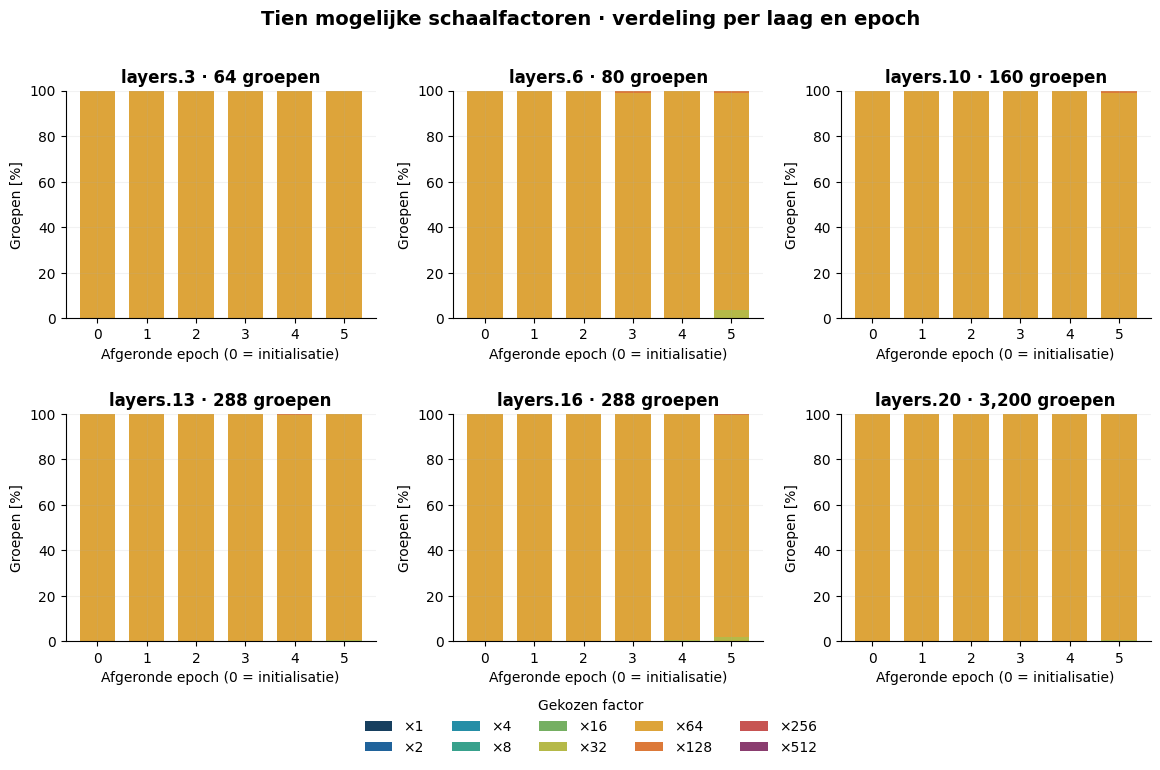

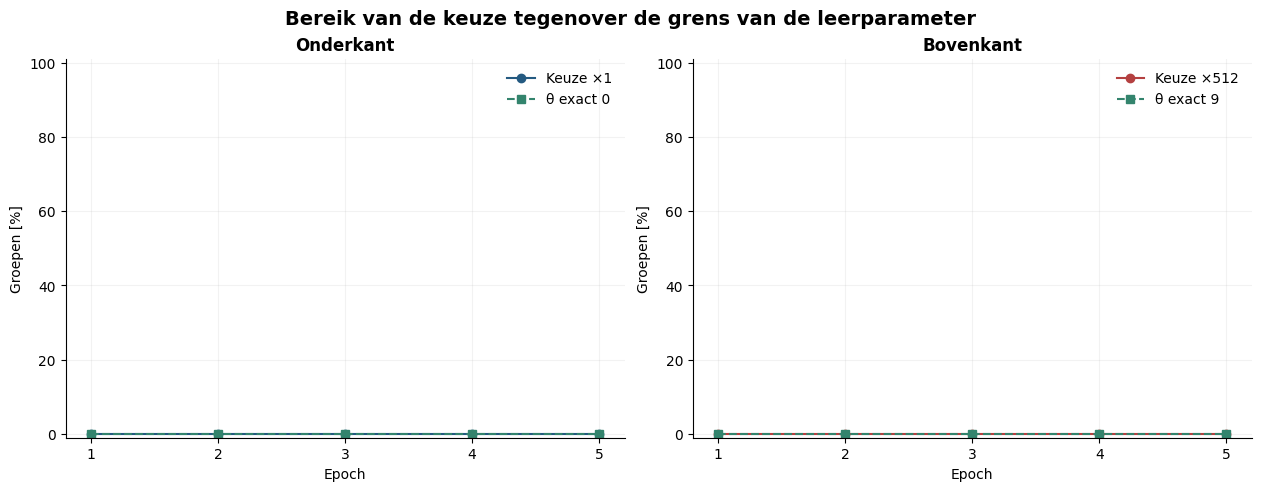

In [8]:
display(Markdown(ns.scale_learning_markdown(run)))
display(ns.scale_table(run).round(8))
figures['scale_choices'] = ns.plot_scale_choices(run)
display(figures['scale_choices'])
plt.close(figures['scale_choices'])
figures['scale_boundaries'] = ns.plot_scale_boundaries(run)
display(figures['scale_boundaries'])
plt.close(figures['scale_boundaries'])


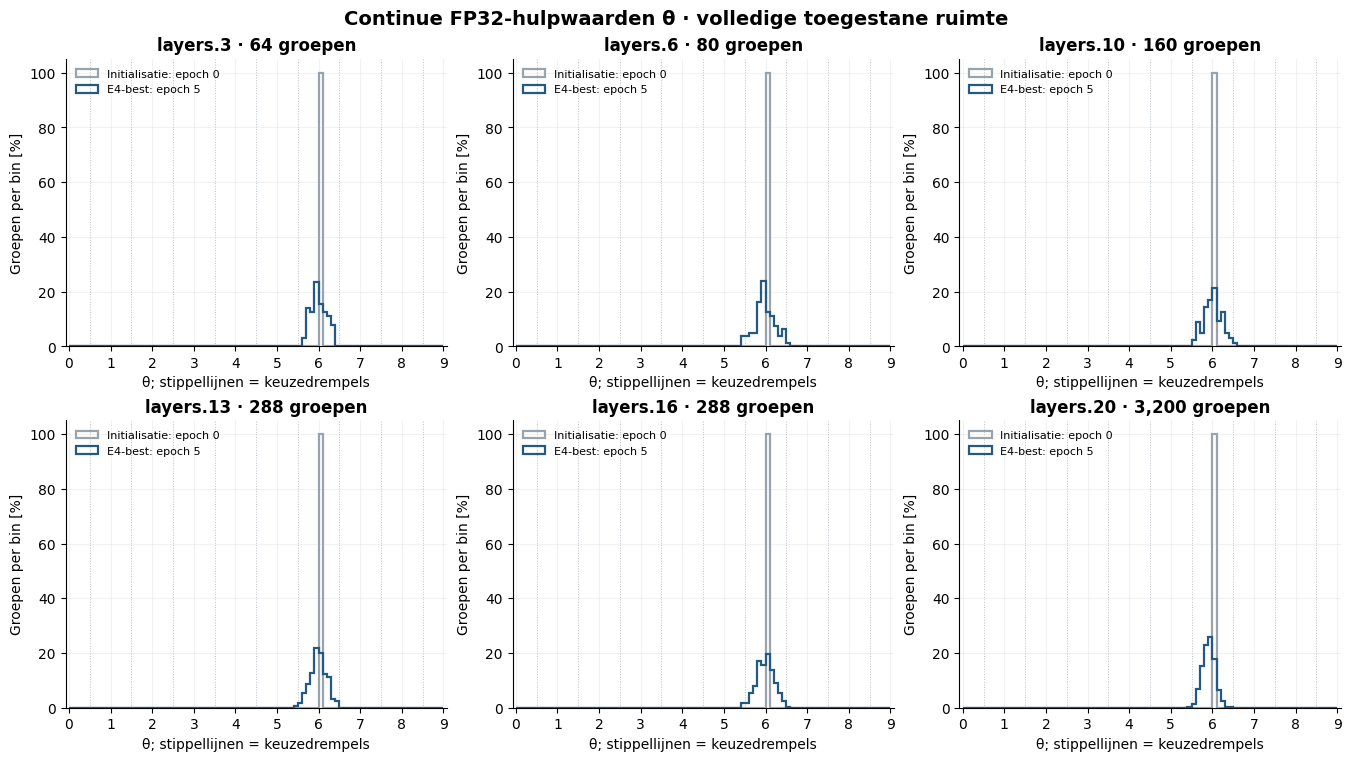

In [9]:
figures['theta_distributions'] = ns.plot_theta_distributions(run)
display(figures['theta_distributions'])
plt.close(figures['theta_distributions'])


### Wissels, spronggrootte, gradients en projectie

Iedere verandering van de harde offset na een optimizerupdate telt als één wissel. Een sprong van +5 naar +7 telt dus als **één wissel met afstand twee**. De tabel bewaart ook de som van sprongafstanden en de grootste sprong. Het aantal unieke wisselende groepen telt elke groep maximaal eenmaal per epoch; netto wijzigingen vergelijken alleen de epochgrenzen. Een groep kan meerdere keren heen en weer wisselen.

De L2-update is het netto verschil van de continue parameters. De gradientgrafiek toont de grootste waargenomen gradientnorm per laag en epoch. De projectietelling telt waarden die na Adam buiten [0,9] vielen en werden teruggezet, inclusief herhalingen. Deze diagnostieken zijn geen bewijs van accuracywinst.


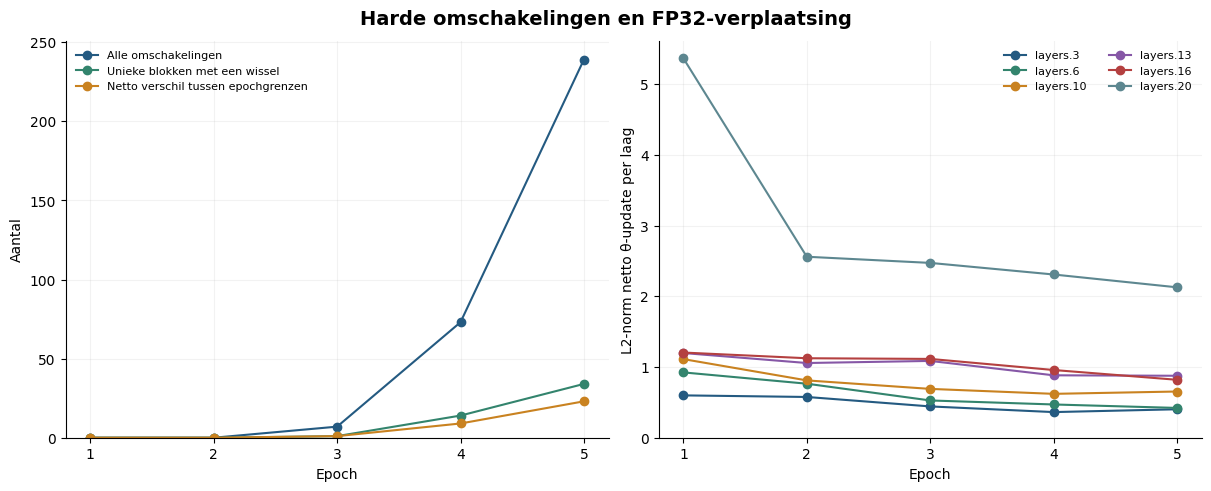

In [10]:
figures['scale_switches'] = ns.plot_scale_switches(run)
display(figures['scale_switches'])
plt.close(figures['scale_switches'])


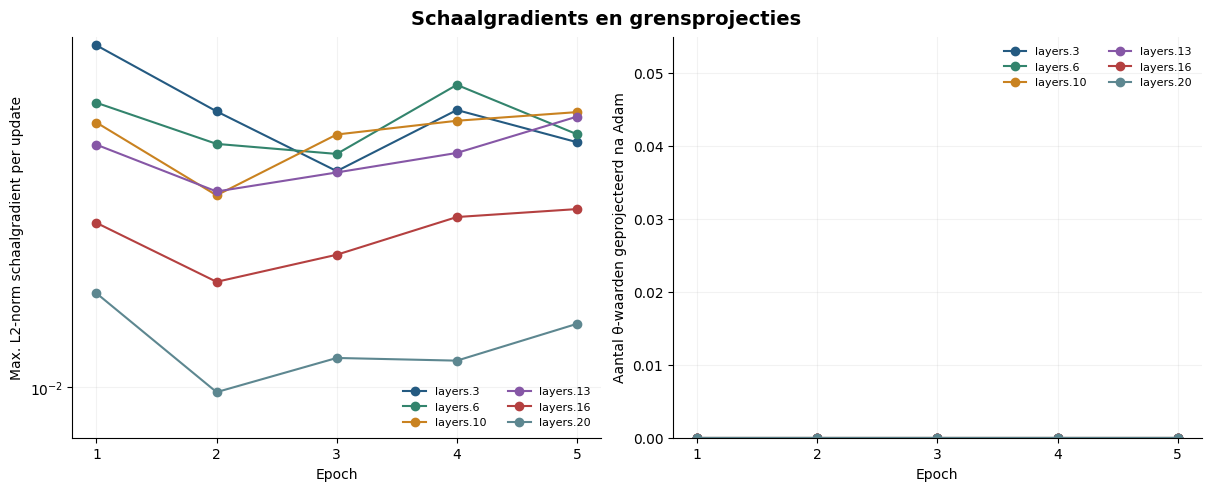

In [11]:
figures['scale_gradients'] = ns.plot_scale_gradients(run)
display(figures['scale_gradients'])
plt.close(figures['scale_gradients'])


## Gemeten trainingsduur en voorlopige projectie naar honderd epochs

**Gemeten som over 5 afgeronde epochs: 338.82 s (5.65 minuten).** Warme epochs volgens het tijdsrapport: **[2, 3, 4, 5]**; mediaan: **68.3 s**. De afzonderlijke projectie geldt voor een **nieuwe volledige run van honderd epochs vanaf initialisatie**. Zij is geen gemeten eindtijd en geen resterende hervattijd. Het waargenomen minimum/maximum van de warme epochs levert een scenario-bereik, geen betrouwbaarheidsinterval. Vijf epochs meten de LR-overgangen op 50/75/90 en langdurige thermische omstandigheden nog niet. Download, installatie, data-inladen en eindrapportage zijn niet inbegrepen. **Geen accuracy voor epoch100 wordt voorspeld.**

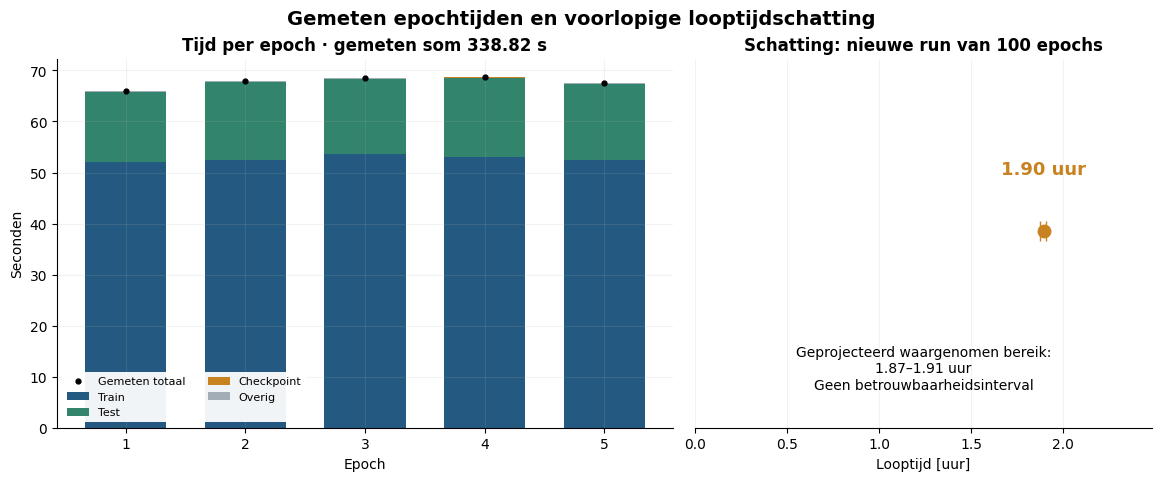

In [12]:
display(Markdown('## Gemeten trainingsduur en voorlopige projectie naar honderd epochs'))
display(Markdown(ns.timing_markdown(run)))
figures['timing'] = ns.plot_timing(run)
display(figures['timing'])
plt.close(figures['timing'])


## GPU-geheugen

De opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.

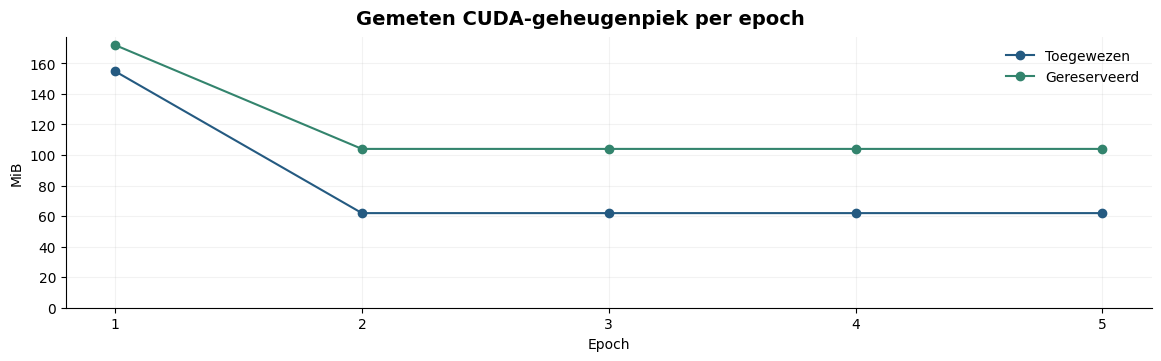

In [13]:
display(Markdown('## GPU-geheugen\n\nDe opgeslagen pieken betreffen de PyTorch CUDA-allocator. Zij meten niet alle GPU-processen of compacte native MX-uitvoering. Ontbrekende waarden blijven ontbrekend.'))
figures['gpu_memory'] = ns.plot_memory(run)
display(figures['gpu_memory'])
plt.close(figures['gpu_memory'])


In [14]:
display(Markdown('## Opgeslagen technische controles\n\nDeze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.'))
display(ns.audit_table(run))
display(Markdown('### Gewichtsupdates\n\nDe mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.'))
display(ns.weight_update_table(run))
display(Markdown('### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint'))
display(ns.export_table(run))


## Opgeslagen technische controles

Deze tabellen rapporteren bestaande controles uit de run. Het notebook voert geen nieuwe gradient-, model- of checkpointcontrole uit.

,Opgeslagen controle,Resultaat volgens rapport
0,Gradientcontrole vóór iedere gezamenlijke update,True
1,FP32-masters en Adam-momenten gecontroleerd,True
2,Geleerde schaalcorrectie ingeschakeld,True
3,Schaalkeuzes en θ-staten onafhankelijk consistent,True
4,E2M1 behoudt de E2M3-schaal,True
5,Eén E4-bron per laag en minibatch,True
6,Broncache leeg vóór iedere optimizerupdate,True
7,BN-tellers correct in elke opgeslagen epoch,True
8,Evaluatie zonder optimizerupdates,True
9,Bronbestanden ongewijzigd,True


### Gewichtsupdates

De mastergewichten zijn dezelfde gedeelde tensors. De herhaalde masterkolommen per modus mogen **niet bij elkaar worden opgeteld**; code- en schaalwijzigingen behoren wel bij het betreffende formaat.

,epoch,weight_format,layer,master_changed_values,master_update_l2,master_dtype,changed_element_codes_including_padding,changed_scale_codes
0,1,MXFP4_E2M1,layers.3,1728,1.454144,torch.float32,1115,0
1,1,MXFP6_E2M3,layers.3,1728,1.454144,torch.float32,1560,0
2,1,MXFP8_E4M3,layers.3,1728,1.454144,torch.float32,1623,0
3,1,MXFP4_E2M1,layers.6,2304,1.745100,torch.float32,1398,1
4,1,MXFP6_E2M3,layers.6,2304,1.745100,torch.float32,2070,1
...,...,...,...,...,...,...,...,...
85,5,MXFP6_E2M3,layers.16,9216,1.382012,torch.float32,8012,4
86,5,MXFP8_E4M3,layers.16,9216,1.382012,torch.float32,8228,0
87,5,MXFP4_E2M1,layers.20,102384,5.601587,torch.float32,56440,449
88,5,MXFP6_E2M3,layers.20,102384,5.601587,torch.float32,88429,449


### Eén opgeslagen E4M3-bron en twee afgeleide exports per geselecteerd checkpoint

,Rol,Epoch,Gewichtsformaat,Bestand,Bestandsbytes,Gewichten exact gereconstrueerd,Zes MX-masters afwezig,FP32-schaalproxies afwezig,Gepakte keuze-informatie [bytes],Eigen schaaloffsets,E4-bronschaal behouden,Afgeleid uit opgeslagen bron,Masters gelezen voor afleiding,Volledige testset opnieuw uitgevoerd,Bron-SHA256
0,best_E4M3_test,5,MXFP8_E4M3,mx_source_MXFP8_E4M3_best.pt,202009,True,True,True,2040,[0],True,False,False,False,c2bc4aff6e1c62f59cf22d5d33a443e70815784b021e21...
1,best_E4M3_test,5,MXFP6_E2M3,mx_derived_MXFP6_E2M3_best.pt,169369,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,c2bc4aff6e1c62f59cf22d5d33a443e70815784b021e21...
2,best_E4M3_test,5,MXFP4_E2M1,mx_derived_MXFP4_E2M1_best.pt,136793,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,c2bc4aff6e1c62f59cf22d5d33a443e70815784b021e21...
3,last_epoch,5,MXFP8_E4M3,mx_source_MXFP8_E4M3_last.pt,202009,True,True,True,2040,[0],True,False,False,False,c2bc4aff6e1c62f59cf22d5d33a443e70815784b021e21...
4,last_epoch,5,MXFP6_E2M3,mx_derived_MXFP6_E2M3_last.pt,169369,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,c2bc4aff6e1c62f59cf22d5d33a443e70815784b021e21...
5,last_epoch,5,MXFP4_E2M1,mx_derived_MXFP4_E2M1_last.pt,136793,True,True,True,2040,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]",False,True,False,False,c2bc4aff6e1c62f59cf22d5d33a443e70815784b021e21...


## Opslagkosten van meer keuzemogelijkheden

Een compacte flexibele E4-bron bewaart nu **4 bits per groep** voor de gekozen offset. Tien mogelijkheden passen in een nibble; waarden10–15 zijn ongeldig. Voor 4.080 groepen zijn dit **2.040 bytes**, tegenover **510 bytes** voor de binaire keuze: **1.530 bytes extra**. Een losse lagere uitvoerprecisie heeft de gekozen offset al verwerkt in zijn E8M0-schaal; daar wordt de keuze-index niet nogmaals bijgeteld.

Er blijft één FP32-parameter per groep. Parameter, gradient en twee FP32-Adam-momenten vragen analytisch **65.280 extra bytes** ten opzichte van vaste schalen, evenveel als bij de binaire leerproef. Tijdelijke buffers, activaties, optimizerstaptellers en allocatoroverhead zijn niet inbegrepen. De grafiek toont deze onderdelen afzonderlijk, niet totale VRAM of de grootte van `.pt`-bestanden.


,Variant,Keuzebits per groep,Groepen,Compacte keuzebytes,Extra FP32 theta+gradient+Adam [bytes]
0,Vaste factor,0,4080,0,0
1,Twee leerbare keuzes,1,4080,510,65280
2,Tien leerbare keuzes,4,4080,2040,65280


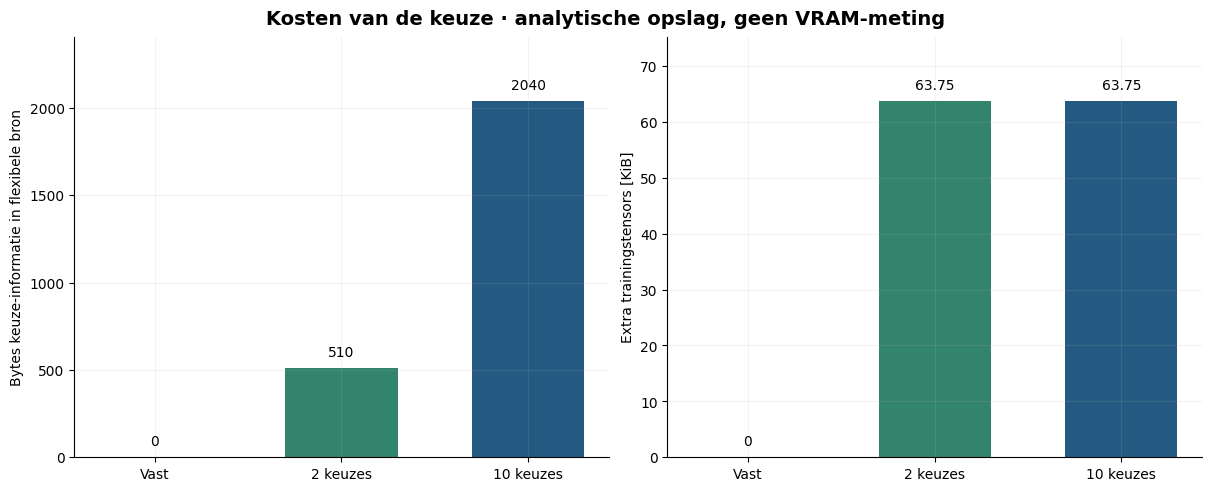

In [15]:
display(ns.storage_cost_table(run))
figures['storage_cost'] = ns.plot_storage_cost(run)
display(figures['storage_cost'])
plt.close(figures['storage_cost'])


## Interpretatie en grenzen

De gerichte wijziging tegenover de binaire leerproef is **tien gehele offsets 0..9 in plaats van twee offsets 5/6**, met bijhorende ruimere parametergrenzen. De groepindeling, oorspronkelijke modelinitialisatie, θ-init6, losses, drie passes, schaalgradient en optimizerinstellingen zijn behouden. De E4-bronschalen blijven dynamisch volgens dezelfde encoder. De gewichtsgradient blijft identity-STE naar G(W), zonder vermenigvuldiging met de gekozen schaalfactor.

Meer keuzes vergroten het bereik; zij voegen geen tussenwaarden tussen ×32 en ×64 toe. Een lage accuracy, constante voorspelling of weinig harde wissels is een onderzoeksuitkomst wanneer de technische controles slagen. Bekijk accuracy, harde test-CE, voorspeldistributie en schaalgedrag samen. Deze korte proef bepaalt niet welk bereik, welke gradientbenadering of welk bevriestijdstip optimaal is.

De LR-planning blijft die van honderd epochs; de huidige executable stopt op vijf. Een later experiment met leren tot100 en eventueel een tak vanaf checkpoint50 wordt hier niet uitgevoerd. De onafhankelijke schaal per exponentbreedte is eveneens een latere onderzoeksrichting, geen onderdeel van deze proef.

Looptijden voor honderd epochs zijn projecties. CUDA volgt de oorspronkelijke backend en biedt geen bitexacte herhaal- of hervatgarantie. De FP32-emulator meet geen native MX-hardwaredoorvoer of energie. De officiële testset wordt ook voor checkpointselectie gebruikt; de geselecteerde score is geen onafhankelijke eindtestschatting.


In [16]:
if SAVE_FIGURES:
    analysis_dir = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', analysis_dir)
else:
    print('Alleen analyse in het notebook; geen figuren naar schijf geschreven.')
print('Ingelezen resultaatmap:', run.path)
display(pd.DataFrame({'Ingelezen bestand': [str(path.relative_to(run.path)) if path.is_relative_to(run.path) else str(path) for path in run.input_files]}))


Alleen analyse in het notebook; geen figuren naar schijf geschreven.
Ingelezen resultaatmap: C:\Users\renzo\master-thesis-mx\mx_runs\mx_triple_learned_scale10_pilot5\20261104_185824_003629_joint_run


,Ingelezen bestand
0,run_report.json
1,history.json
2,training_summary.json
3,checkpoint_selection.json
4,timing_estimate.json
5,epoch_metrics.csv
6,selected_metrics.csv
7,epoch_times.csv
8,weight_updates.csv
9,scale_epoch_metrics.csv
